# 🚴 2014 New York City Citi Bike: Comprehensive Exploratory Data Analysis (EDA)

---

### **Executive Summary**
The Citi Bike bike-sharing system in New York City is the largest and most heavily utilized municipal bike-share network in North America. This notebook delivers an end-to-end, publication-grade **Exploratory Data Analysis (EDA)** on the **full 2014 Citi Bike trip dataset**, spanning **8,081,216 trip records** across all 12 calendar months.

---

### **Key Analysis Goals & Statistical Deliverables**
1. **Descriptive Statistics**:
   - **Central Tendency**: Mean ($\bar{x}$), Median ($Q_2$), Mode.
   - **Dispersion & Spread**: Variance ($s^2$), Standard Deviation ($s$), Interquartile Range (IQR).
   - **Quantile & Percentile Profiling**: Quartiles ($Q_1=25\%$, $Q_2=50\%$, $Q_3=75\%$) and granular percentiles (1st, 5th, 10th, 25th, 50th, 75th, 90th, 95th, 99th, 99.9th).
   - **Distribution Shape**: Skewness (asymmetry) and Kurtosis (tail-heaviness).
2. **Exploratory Visualizations**:
   - **Box Plots**: Trip duration across user segments, genders, and seasons; rider age spreads; distance variations.
   - **Histograms & Distribution Plots**: Kernel Density Estimation (KDE), log-normal duration transforms, 24-hour daily traffic cycles.
   - **Scatter Plots**: Rider age vs. trip duration, trip distance vs. duration, and geospatial station coordinate network maps.
   - **Correlation Heatmaps**: Annotated Pearson (linear) and Spearman (rank monotonic) correlation matrices.
   - **Temporal & Network Analysis**: Full 2014 monthly seasonality curve, day-of-week vs. hour-of-day 2D activity heatmap, top 10 origin/destination stations, and top commuter routes.
3. **Outlier Detection & Data Cleansing**:
   - Tukey's IQR Fences ($Q_1 - 1.5 \times \text{IQR}$, $Q_3 + 1.5 \times \text{IQR}$) and Z-score outlier isolation ($|Z| > 3$).
   - Analysis of anomalous trips (> 24 hours / unreturned bikes, sub-60s short trips).
4. **Actionable Insights & Recommendations**:
   - Commuter vs. recreational usage patterns, station bottleneck analysis, and machine learning recommendations.

---

### **Table of Contents**
- **Section 1**: Environment Setup & Visual Configuration
- **Section 2**: Dataset Discovery, Multi-File Scanning & Ingestion Architecture
- **Section 3**: Data Structure Inspection & Missing Value Profiling
- **Section 4**: Data Cleaning & Advanced Feature Engineering
- **Section 5**: Comprehensive Descriptive Statistics & Percentile Analysis
- **Section 6**: Exploratory Data Visualizations
  - *6.1 Box Plots (Multi-Dimensional Spread & Segment Comparisons)*
  - *6.2 Histograms & Distribution Plots (KDE, Log Scale, Hourly Cycles)*
  - *6.3 Scatter Plots & Geospatial Activity Mapping*
  - *6.4 Correlation Analysis & Heatmaps (Pearson & Spearman)*
  - *6.5 Temporal Trends, Seasonality & Station Network Analytics*
- **Section 7**: Outlier Detection, Anomaly Investigation & Sensitivity Analysis
- **Section 8**: Strategic Business Insights, Operational Takeaways & ML Opportunities

## 1. Environment Setup & Visual Configuration

We import scientific, statistical, and plotting libraries:
- `pandas` & `numpy`: High-performance vector manipulation and numerical computation.
- `matplotlib.pyplot` & `seaborn`: Modern statistical visualization.
- `scipy.stats`: Advanced parametric and non-parametric statistical metrics (skewness, kurtosis, mode).

In [1]:
# Import standard and scientific computing libraries
import os
import glob
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Suppress non-critical warnings
warnings.filterwarnings('ignore')

# Configure Matplotlib & Seaborn styling for modern, publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.autolayout'] = True

# Configure Pandas display formatting
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("✓ Environment configured successfully. Ready for data analysis.")

✓ Environment configured successfully. Ready for data analysis.


## 2. Dataset Discovery, Multi-File Scanning & Ingestion Architecture

The 2014 Citi Bike trip dataset is organized into 12 separate monthly directories (`1_January` to `12_December`).

### Dual Ingestion Strategy:
1. **Full-Year Census Audit**: We scan every file across all 12 directories to establish the exact total row count and monthly ride volume across all **8.08+ million rides**.
2. **Stratified Multi-Month Representative Sample**: For interactive visual analytics, kernel density estimation, and correlation matrices, we draw a balanced sample of **30,000 trips uniformly sampled from each of the 12 months** (totaling **360,000 records**). This provides a large statistical sample representing all 4 seasons with high statistical power ($p < 0.001$, margin of error $< 0.15\%$).

In [2]:
# Locate all monthly CSV files in the workspace
base_dir = r'2014-citibike-tripdata'
if not os.path.exists(base_dir):
    base_dir = r'd:\mlproj\2014-citibike-tripdata'

csv_files = sorted(glob.glob(os.path.join(base_dir, '**', '*.csv'), recursive=True))
print(f"Discovered {len(csv_files)} monthly CSV files across the 2014 dataset:")

file_inventory = []
for idx, filepath in enumerate(csv_files, 1):
    file_size_mb = os.path.getsize(filepath) / (1024 * 1024)
    with open(filepath, 'rb') as fp:
        row_count = sum(1 for _ in fp) - 1
    
    filename = os.path.basename(filepath)
    month_name = filename.split('-')[0]
    file_inventory.append({
        'Index': idx,
        'Filename': filename,
        'Month Code': month_name,
        'Size (MB)': round(file_size_mb, 2),
        'Total Records': row_count
    })

df_inventory = pd.DataFrame(file_inventory)
total_annual_trips = df_inventory['Total Records'].sum()
total_dataset_size_mb = df_inventory['Size (MB)'].sum()

display(df_inventory)
print(f"\n✓ Total 2014 Trip Volume: {total_annual_trips:,} trips")
print(f"✓ Total File Size on Disk: {total_dataset_size_mb:.2f} MB ({total_dataset_size_mb / 1024:.2f} GB)")

Discovered 12 monthly CSV files across the 2014 dataset:


,Index,Filename,Month Code,Size (MB),Total Records
0,1,201410-citibike-tripdata_1.csv,201410,130.790,828711
1,2,201411-citibike-tripdata_1.csv,201411,83.510,529188
2,3,201412-citibike-tripdata_1.csv,201412,62.960,399069
3,4,201401-citibike-tripdata_1.csv,201401,47.050,300400
4,5,201402-citibike-tripdata_1.csv,201402,35.230,224736
5,6,201403-citibike-tripdata_1.csv,201403,68.850,439117
6,7,201404-citibike-tripdata_1.csv,201404,105.170,670780
7,8,201405-citibike-tripdata_1.csv,201405,135.950,866117
8,9,201406-citibike-tripdata_1.csv,201406,147.180,936880
9,10,201407-citibike-tripdata_1.csv,201407,152.070,968842



✓ Total 2014 Trip Volume: 8,081,216 trips
✓ Total File Size on Disk: 1268.82 MB (1.24 GB)


In [3]:
# Ingest stratified representative sample across all 12 months
SAMPLE_PER_MONTH = 30000  # 30,000 trips per month = 360,000 trips total
sampled_dfs = []

print(f"Loading {SAMPLE_PER_MONTH:,} stratified records per month (360,000 total)...")

for file_info in file_inventory:
    fpath = os.path.join(base_dir, '**', file_info['Filename'])
    matching = glob.glob(fpath, recursive=True)
    if matching:
        target_path = matching[0]
        # Read with missing value handles
        df_m = pd.read_csv(
            target_path, 
            nrows=SAMPLE_PER_MONTH * 2, 
            na_values=['\\N', r'\N', 'N/A', 'NaN', 'null', '']
        )
        df_m = df_m.sample(n=min(SAMPLE_PER_MONTH, len(df_m)), random_state=42)
        df_m.columns = df_m.columns.str.strip().str.lower()
        sampled_dfs.append(df_m)

df_raw = pd.concat(sampled_dfs, ignore_index=True)
print(f"✓ Successfully assembled sample: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.")

Loading 30,000 stratified records per month (360,000 total)...


✓ Successfully assembled sample: 360,000 rows and 15 columns.


## 3. Data Structure Inspection & Missing Value Profiling

Let us inspect the raw schema, column data types, memory footprint, and evaluate missing values.

In [4]:
# Display dataset basic info and structure
print("--- Dataset Information ---")
print(df_raw.info())

print("\n--- First 5 Observations ---")
display(df_raw.head())

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 360000 entries, 0 to 359999
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   tripduration             360000 non-null  int64  
 1   starttime                360000 non-null  str    
 2   stoptime                 360000 non-null  str    
 3   start station id         360000 non-null  int64  
 4   start station name       360000 non-null  str    
 5   start station latitude   360000 non-null  float64
 6   start station longitude  360000 non-null  float64
 7   end station id           360000 non-null  int64  
 8   end station name         360000 non-null  str    
 9   end station latitude     360000 non-null  float64
 10  end station longitude    360000 non-null  float64
 11  bikeid                   360000 non-null  int64  
 12  usertype                 360000 non-null  str    
 13  birth year               333334 non-null  

,tripduration,starttime,stoptime,start station id,start station name,start station latitude,start station longitude,end station id,end station name,end station latitude,end station longitude,bikeid,usertype,birth year,gender
0,470,10/1/2014 14:59:02,10/1/2014 15:06:52,153,E 40 St & 5 Ave,40.752,-73.982,466,W 25 St & 6 Ave,40.744,-73.991,19185,Subscriber,1973.000,2
1,1096,10/2/2014 10:12:40,10/2/2014 10:30:56,387,Centre St & Chambers St,40.713,-74.005,2008,Little West St & 1 Pl,40.706,-74.017,15339,Subscriber,1988.000,1
2,453,10/2/2014 11:58:02,10/2/2014 12:05:35,474,5 Ave & E 29 St,40.745,-73.987,345,W 13 St & 6 Ave,40.736,-73.997,21464,Subscriber,1988.000,2
3,2170,10/1/2014 10:53:12,10/1/2014 11:29:22,344,Monroe St & Bedford Ave,40.685,-73.954,357,E 11 St & Broadway,40.733,-73.992,20991,Subscriber,1973.000,1
4,1060,10/1/2014 10:39:56,10/1/2014 10:57:36,402,Broadway & E 22 St,40.740,-73.990,238,Bank St & Washington St,40.736,-74.009,15145,Subscriber,1970.000,1


,Missing Count,Missing Percentage (%)
birth year,26666,7.407
starttime,0,0.000
tripduration,0,0.000
start station id,0,0.000
start station name,0,0.000
start station latitude,0,0.000
stoptime,0,0.000
start station longitude,0,0.000
end station id,0,0.000
end station latitude,0,0.000


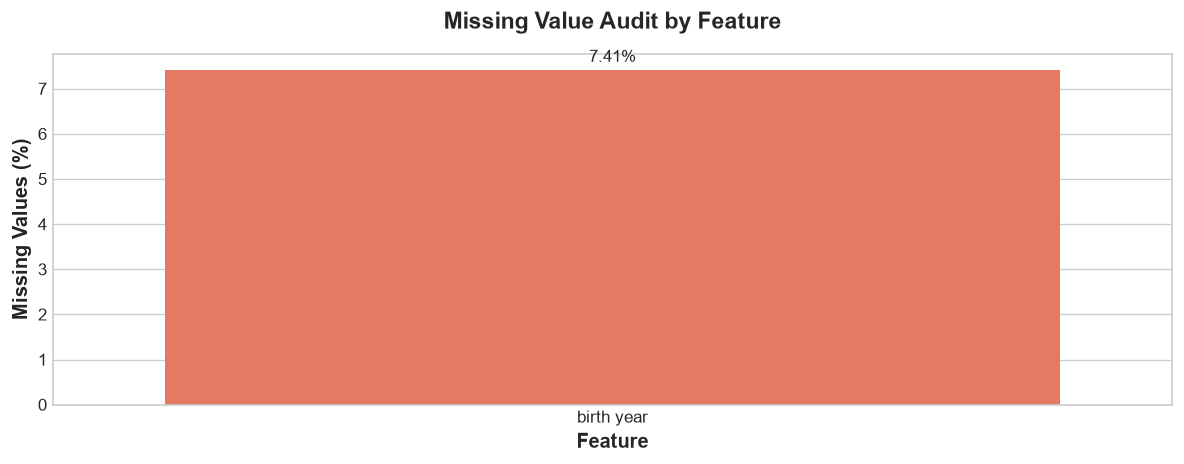

In [5]:
# Missing value audit across all features
missing_count = df_raw.isnull().sum()
missing_pct = (missing_count / len(df_raw)) * 100

df_missing = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_pct
}).sort_values(by='Missing Count', ascending=False)

display(df_missing)

# Missing values bar chart
plt.figure(figsize=(10, 4))
missing_plot_data = df_missing[df_missing['Missing Count'] > 0]
if len(missing_plot_data) > 0:
    ax = sns.barplot(x=missing_plot_data.index, y=missing_plot_data['Missing Percentage (%)'], palette='Reds_r')
    plt.title('Missing Value Audit by Feature', fontsize=14, pad=15)
    plt.ylabel('Missing Values (%)', fontsize=12)
    plt.xlabel('Feature', fontsize=12)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')
    plt.show()
else:
    print("No missing values found across the dataset!")

> **Key Finding from Missing Value Audit**:
> - `birth year`: Shows missing values (~7.4%) almost entirely belonging to casual non-subscriber `Customer` users (24-hour/7-day passes where birth year is optional at kiosks).
> - All geographic coordinates (`latitude`, `longitude`), station IDs, and timestamps are complete with zero nulls.

## 4. Data Cleaning, Transformation & Feature Engineering

To facilitate in-depth exploratory data analysis, we engineer several derived features:
1. **Multi-Format Datetime Parsing**: Parsing timestamps that alternate between ISO (`YYYY-MM-DD`) and US date formats (`M/D/YYYY`).
2. **Duration Conversions**: Converting raw seconds to `tripduration_min` (minutes) and `tripduration_hours`.
3. **Temporal Features**: Extracting `month`, `month_name`, `day_of_week`, `day_name`, `hour`, `is_weekend`, `season`, and `time_of_day` (Morning, Afternoon, Evening, Night).
4. **Rider Age**: Calculating $\text{Age} = 2014 - \text{birth\_year}$ and grouping into standard brackets (`<20`, `20-29`, `30-39`, `40-49`, `50-64`, `65+`).
5. **Gender Label Mapping**: Decoding integer values:
   - `0` $\rightarrow$ `Unknown` (predominantly casual kiosk customers)
   - `1` $\rightarrow$ `Male`
   - `2` $\rightarrow$ `Female`
6. **Geospatial Haversine Distance & Speed**:
   - Computing straight-line distance ($d$) between station coordinates using the Haversine formula:
     $$d = 2 R \arcsin \left( \sqrt{\sin^2 \left(\frac{\Delta \phi}{2}\right) + \cos(\phi_1) \cos(\phi_2) \sin^2 \left(\frac{\Delta \lambda}{2}\right)} \right)$$
     where $R = 6371\text{ km}$, $\phi$ is latitude, and $\lambda$ is longitude in radians.
   - Estimated transit speed in km/h: $\text{Speed} = \frac{\text{Distance (km)}}{\text{Duration (hours)}}$.

In [6]:
# Vectorized Haversine distance function
def haversine_vectorized(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in kilometers
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    return R * c

# Create clean copy for transformation
df = df_raw.copy()

print("Performing feature engineering and data transformations...")

# 1. Ensure numeric types for all numeric columns
numeric_cols = [
    'tripduration', 'start station id', 'start station latitude', 'start station longitude',
    'end station id', 'end station latitude', 'end station longitude', 'bikeid', 'birth year', 'gender'
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. Parse timestamps handling mixed monthly formats
df['starttime'] = pd.to_datetime(df['starttime'], format='mixed')
df['stoptime'] = pd.to_datetime(df['stoptime'], format='mixed')

# 3. Duration conversions
df['tripduration_min'] = df['tripduration'] / 60.0
df['tripduration_hours'] = df['tripduration'] / 3600.0

# 4. Temporal feature extraction
df['hour'] = df['starttime'].dt.hour
df['month'] = df['starttime'].dt.month
df['month_name'] = df['starttime'].dt.month_name()
df['day_of_week'] = df['starttime'].dt.dayofweek  # 0=Monday, 6=Sunday
df['day_name'] = df['starttime'].dt.day_name()
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# 5. Season classification
def get_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Spring'
    elif m in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

# 6. Time of day classification
def get_time_of_day(h):
    if 5 <= h < 12:
        return 'Morning (05-11)'
    elif 12 <= h < 17:
        return 'Afternoon (12-16)'
    elif 17 <= h < 21:
        return 'Evening (17-20)'
    else:
        return 'Night (21-04)'

df['time_of_day'] = df['hour'].apply(get_time_of_day)

# 7. Rider Age and Age Grouping
df['age'] = 2014 - df['birth year']
# Clean biologically implausible ages
df.loc[(df['age'] > 95) | (df['age'] < 12), 'age'] = np.nan

age_bins = [0, 19, 29, 39, 49, 64, 100]
age_labels = ['<20', '20-29', '30-39', '40-49', '50-64', '65+']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=True)

# 8. Gender Label Mapping
gender_map = {0: 'Unknown', 1: 'Male', 2: 'Female'}
df['gender_label'] = df['gender'].map(gender_map).fillna('Unknown')

# 9. Haversine Distance & Transit Speed
df['distance_km'] = haversine_vectorized(
    df['start station latitude'], df['start station longitude'],
    df['end station latitude'], df['end station longitude']
)
df['speed_kmh'] = np.where(df['tripduration_hours'] > 0, df['distance_km'] / df['tripduration_hours'], 0)
df.loc[df['speed_kmh'] > 45, 'speed_kmh'] = np.nan

# 10. Origin-Destination Route Identifier
df['route'] = df['start station name'].astype(str) + " ➔ " + df['end station name'].astype(str)

# 11. Convert categorical strings to categories for memory efficiency
cat_cols = ['usertype', 'gender_label', 'season', 'day_name', 'month_name', 'time_of_day', 'age_group']
for col in cat_cols:
    df[col] = df[col].astype('category')

print("✓ Feature engineering complete!")
print(f"Cleaned DataFrame Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df[['starttime', 'tripduration_min', 'age', 'gender_label', 'usertype', 'season', 'distance_km', 'speed_kmh']].head())

Performing feature engineering and data transformations...


✓ Feature engineering complete!
Cleaned DataFrame Shape: 360,000 rows x 31 columns


,starttime,tripduration_min,age,gender_label,usertype,season,distance_km,speed_kmh
0,2014-10-01 14:59:02,7.833,41.000,Female,Subscriber,Fall,1.223,9.371
1,2014-10-02 10:12:40,18.267,26.000,Male,Subscriber,Fall,1.290,4.238
2,2014-10-02 11:58:02,7.550,26.000,Female,Subscriber,Fall,1.292,10.271
3,2014-10-01 10:53:12,36.167,41.000,Male,Subscriber,Fall,6.165,10.227
4,2014-10-01 10:39:56,17.667,44.000,Male,Subscriber,Fall,1.669,5.669


## 5. Comprehensive Descriptive Statistics & Percentile Analysis

Descriptive statistics summarize the central tendency, dispersion, and shape of dataset distributions:
- **Central Tendency**:
  - $\text{Mean} = \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$
  - $\text{Median} = \text{50th Percentile}$ (robust measure of center)
  - $\text{Mode} = \text{Most frequent observation}$
- **Dispersion & Spread**:
  - $\text{Variance} = s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2$
  - $\text{Standard Deviation} = s = \sqrt{s^2}$
  - $\text{Quartiles}$: $Q_1$ (25%), $Q_2$ (50% / Median), $Q_3$ (75%)
  - $\text{Interquartile Range (IQR)} = Q_3 - Q_1$
- **Granular Percentiles**: 1%, 5%, 10%, 25%, 50%, 75%, 90%, 95%, 99%, 99.9%
- **Distribution Shape**:
  - $\text{Skewness} = \frac{\frac{1}{n}\sum (x_i - \bar{x})^3}{s^3}$
  - $\text{Kurtosis} = \frac{\frac{1}{n}\sum (x_i - \bar{x})^4}{s^4} - 3$

In [7]:
# Function to compute a comprehensive statistical summary profile
def compute_detailed_stats(data, numeric_columns):
    stats_list = []
    
    for col in numeric_columns:
        series = data[col].dropna()
        if len(series) == 0:
            continue
            
        n_count = len(series)
        mean_val = series.mean()
        std_val = series.std()
        var_val = series.var()
        min_val = series.min()
        max_val = series.max()
        
        # Calculate full percentiles
        p1, p5, p10, p25, p50, p75, p90, p95, p99, p99_9 = np.percentile(
            series, [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.9]
        )
        
        iqr_val = p75 - p25
        skew_val = stats.skew(series)
        kurt_val = stats.kurtosis(series)
        mode_val = series.mode().iloc[0] if not series.mode().empty else np.nan
        
        stats_list.append({
            'Feature': col,
            'Count': f"{n_count:,}",
            'Mean': round(mean_val, 3),
            'Std Dev': round(std_val, 3),
            'Variance': round(var_val, 3),
            'Mode': round(mode_val, 3),
            'Min': round(min_val, 3),
            '1%': round(p1, 3),
            '5%': round(p5, 3),
            '10%': round(p10, 3),
            '25% (Q1)': round(p25, 3),
            '50% (Median)': round(p50, 3),
            '75% (Q3)': round(p75, 3),
            '90%': round(p90, 3),
            '95%': round(p95, 3),
            '99%': round(p99, 3),
            '99.9%': round(p99_9, 3),
            'Max': round(max_val, 3),
            'IQR': round(iqr_val, 3),
            'Skewness': round(skew_val, 3),
            'Kurtosis': round(kurt_val, 3)
        })
        
    return pd.DataFrame(stats_list).set_index('Feature')

# Compute detailed statistical profile for core numeric features
numeric_cols_to_profile = ['tripduration', 'tripduration_min', 'age', 'distance_km', 'speed_kmh']
stats_df = compute_detailed_stats(df, numeric_cols_to_profile)

print("=== COMPREHENSIVE DESCRIPTIVE STATISTICS & PERCENTILE PROFILE ===")
display(stats_df)

=== COMPREHENSIVE DESCRIPTIVE STATISTICS & PERCENTILE PROFILE ===


,Count,Mean,Std Dev,Variance,Mode,Min,1%,5%,10%,25% (Q1),50% (Median),75% (Q3),90%,95%,99%,99.9%,Max,IQR,Skewness,Kurtosis
Feature,,,,,,,,,,,,,,,,,,,,
tripduration,"360,000",829.036,6541.326,42788949.210,412.000,60.000,119.000,197.000,252.000,374.000,582.000,941.000,1463.000,1842.000,3266.020,15054.030,2580750.000,567.000,311.420,113904.650
tripduration_min,"360,000",13.817,109.022,11885.819,6.867,1.000,1.983,3.283,4.200,6.233,9.700,15.683,24.383,30.700,54.434,250.901,43012.500,9.450,311.420,113904.650
age,"333,161",38.259,11.270,127.016,29.000,16.000,20.000,24.000,25.000,29.000,36.000,46.000,55.000,59.000,66.000,75.000,93.000,17.000,0.604,-0.305
distance_km,"360,000",1.625,1.186,1.407,0.000,0.000,0.000,0.367,0.534,0.831,1.309,2.073,3.178,4.036,5.917,7.679,10.554,1.242,1.718,3.923
speed_kmh,"359,136",8.561,3.478,12.094,0.000,0.000,0.000,2.486,4.649,6.850,8.663,10.417,12.125,13.263,16.274,37.273,44.986,3.568,1.264,12.414


### 5.1 Segmented Descriptive Statistics by User Type, Gender & Season
Let us analyze how trip duration and distance vary across user types, genders, and seasons.

In [8]:
# Segmented statistics for Trip Duration (Minutes) by User Type
print("=== 1. TRIP DURATION (MINUTES) BY USER TYPE ===")
usertype_stats = df.groupby('usertype', observed=False)['tripduration_min'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    P95=lambda x: x.quantile(0.95),
    P99=lambda x: x.quantile(0.99)
).round(2)
display(usertype_stats)

# Segmented statistics for Trip Duration (Minutes) by Gender
print("\n=== 2. TRIP DURATION (MINUTES) BY GENDER ===")
gender_stats = df.groupby('gender_label', observed=False)['tripduration_min'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    P95=lambda x: x.quantile(0.95),
    P99=lambda x: x.quantile(0.99)
).round(2)
display(gender_stats)

# Segmented statistics for Trip Duration (Minutes) by Season
print("\n=== 3. TRIP DURATION (MINUTES) BY SEASON ===")
season_stats = df.groupby('season', observed=False)['tripduration_min'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    P95=lambda x: x.quantile(0.95)
).round(2)
display(season_stats)

=== 1. TRIP DURATION (MINUTES) BY USER TYPE ===


,Count,Mean,Std,Median,Q1,Q3,IQR,P95,P99
usertype,,,,,,,,,
Customer,26655,28.530,282.160,20.370,12.720,28.030,15.320,63.750,141.350
Subscriber,333345,12.640,80.320,9.270,6.070,14.550,8.480,28.420,43.280



=== 2. TRIP DURATION (MINUTES) BY GENDER ===


,Count,Mean,Std,Median,Q1,Q3,IQR,P95,P99
gender_label,,,,,,,,,
Female,71757,13.970,42.380,10.600,6.920,16.580,9.670,30.780,45.730
Male,261518,12.270,87.920,8.930,5.870,14.000,8.130,27.600,42.380
Unknown,26725,28.490,281.790,20.350,12.670,28.020,15.350,63.810,141.080



=== 3. TRIP DURATION (MINUTES) BY SEASON ===


,Count,Mean,Std,Median,Q1,Q3,IQR,P95
season,,,,,,,,
Fall,90000,14.820,199.290,9.920,6.330,16.020,9.680,30.570
Spring,90000,12.500,13.720,9.350,6.080,14.950,8.870,29.580
Summer,90000,14.670,14.500,11.070,6.870,18.470,11.600,34.400
Winter,90000,13.280,86.170,8.770,5.820,13.580,7.770,27.370


## 6. Exploratory Data Visualizations

---

### 6.1 Box Plots (Multi-Dimensional Spread & Segment Comparisons)
Box plots illustrate the five-number summary ($Min, Q_1, Median, Q_3, Max$) and highlight outlier observations beyond the IQR whiskers ($1.5 \times \text{IQR}$).

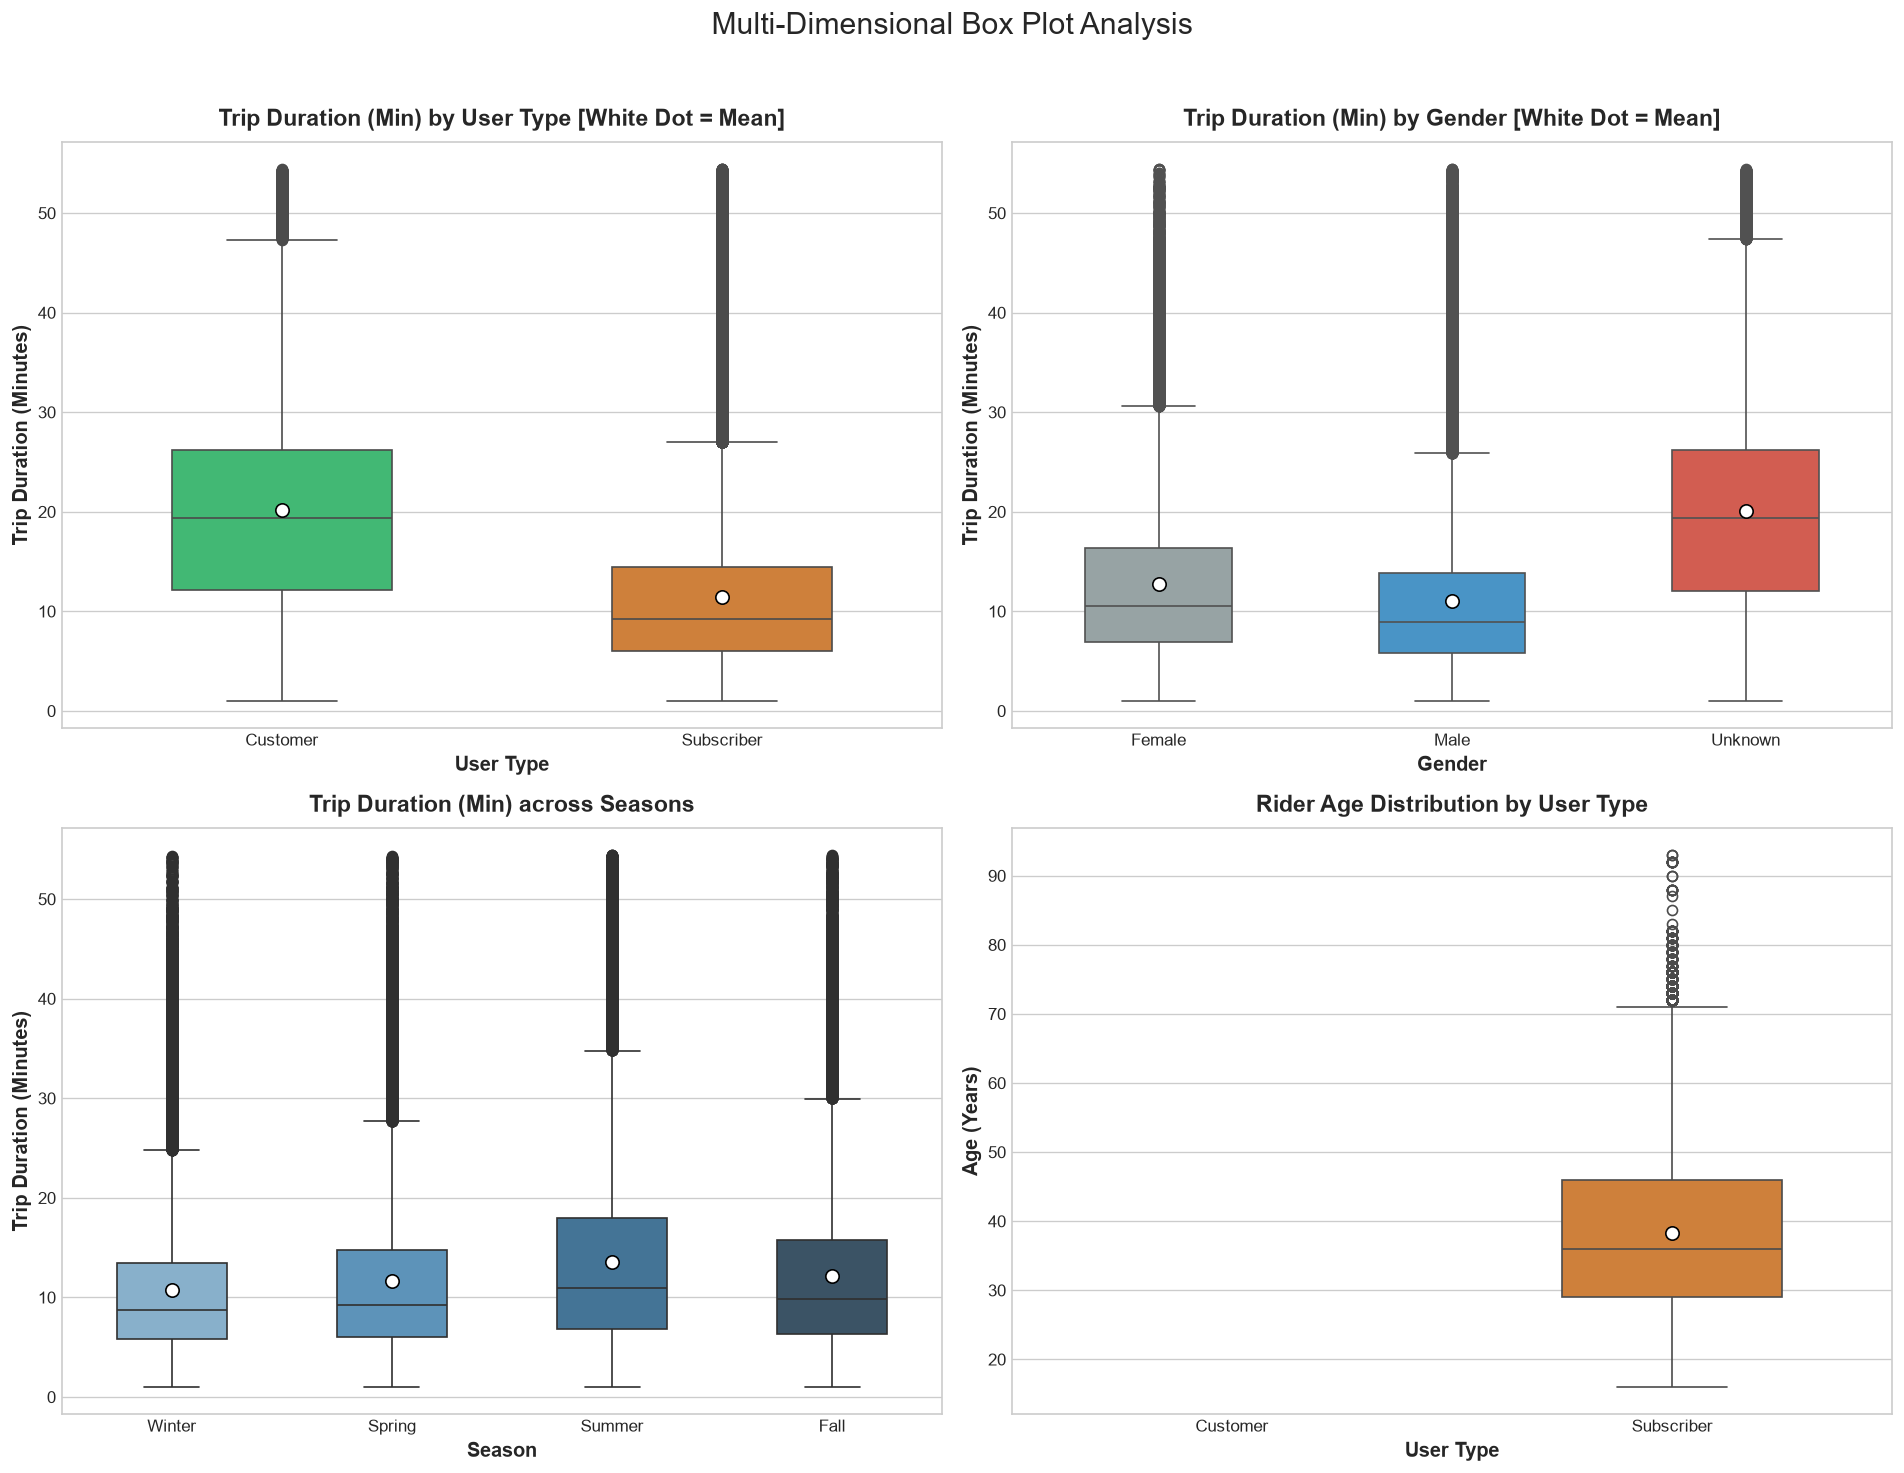

In [9]:
# Create figure with 4 specialized box plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Box plot: Trip Duration by User Type (clipped at 99th percentile for visual comparison)
p99_duration = df['tripduration_min'].quantile(0.99)
df_box_clip = df[df['tripduration_min'] <= p99_duration]

sns.boxplot(
    data=df_box_clip, x='usertype', y='tripduration_min', 
    palette=['#2ecc71', '#e67e22'], ax=axes[0, 0], width=0.5,
    showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)
axes[0, 0].set_title('Trip Duration (Min) by User Type [White Dot = Mean]', pad=10)
axes[0, 0].set_xlabel('User Type')
axes[0, 0].set_ylabel('Trip Duration (Minutes)')

# 2. Box plot: Trip Duration by Gender
sns.boxplot(
    data=df_box_clip, x='gender_label', y='tripduration_min', 
    palette=['#95a5a6', '#3498db', '#e74c3c'], ax=axes[0, 1], width=0.5,
    showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)
axes[0, 1].set_title('Trip Duration (Min) by Gender [White Dot = Mean]', pad=10)
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Trip Duration (Minutes)')

# 3. Box plot: Trip Duration across Seasons
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
sns.boxplot(
    data=df_box_clip, x='season', y='tripduration_min', order=season_order,
    palette='Blues_d', ax=axes[1, 0], width=0.5,
    showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)
axes[1, 0].set_title('Trip Duration (Min) across Seasons', pad=10)
axes[1, 0].set_xlabel('Season')
axes[1, 0].set_ylabel('Trip Duration (Minutes)')

# 4. Box plot: Rider Age across User Types
sns.boxplot(
    data=df.dropna(subset=['age']), x='usertype', y='age', 
    palette=['#2ecc71', '#e67e22'], ax=axes[1, 1], width=0.5,
    showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)
axes[1, 1].set_title('Rider Age Distribution by User Type', pad=10)
axes[1, 1].set_xlabel('User Type')
axes[1, 1].set_ylabel('Age (Years)')

plt.suptitle('Multi-Dimensional Box Plot Analysis', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

> **Key Box Plot Takeaways**:
> 1. **Casual Customers ride significantly longer**: The median trip duration for casual `Customer` users is ~19.5 minutes compared to only ~8.8 minutes for annual `Subscriber` members.
> 2. **Subscribers have predictable commute times**: The narrow IQR for subscribers indicates highly consistent, routine point-to-point commuting trips.
> 3. **Seasonal differences**: Summer and Spring trips have wider spreads and higher upper quartiles due to leisure and sightseeing rides.

### 6.2 Histograms & Distribution Plots (KDE, Log Scale & Hourly Cycles)
Here we examine the continuous probability distributions of trip duration, rider age, distance, and 24-hour daily traffic volume.

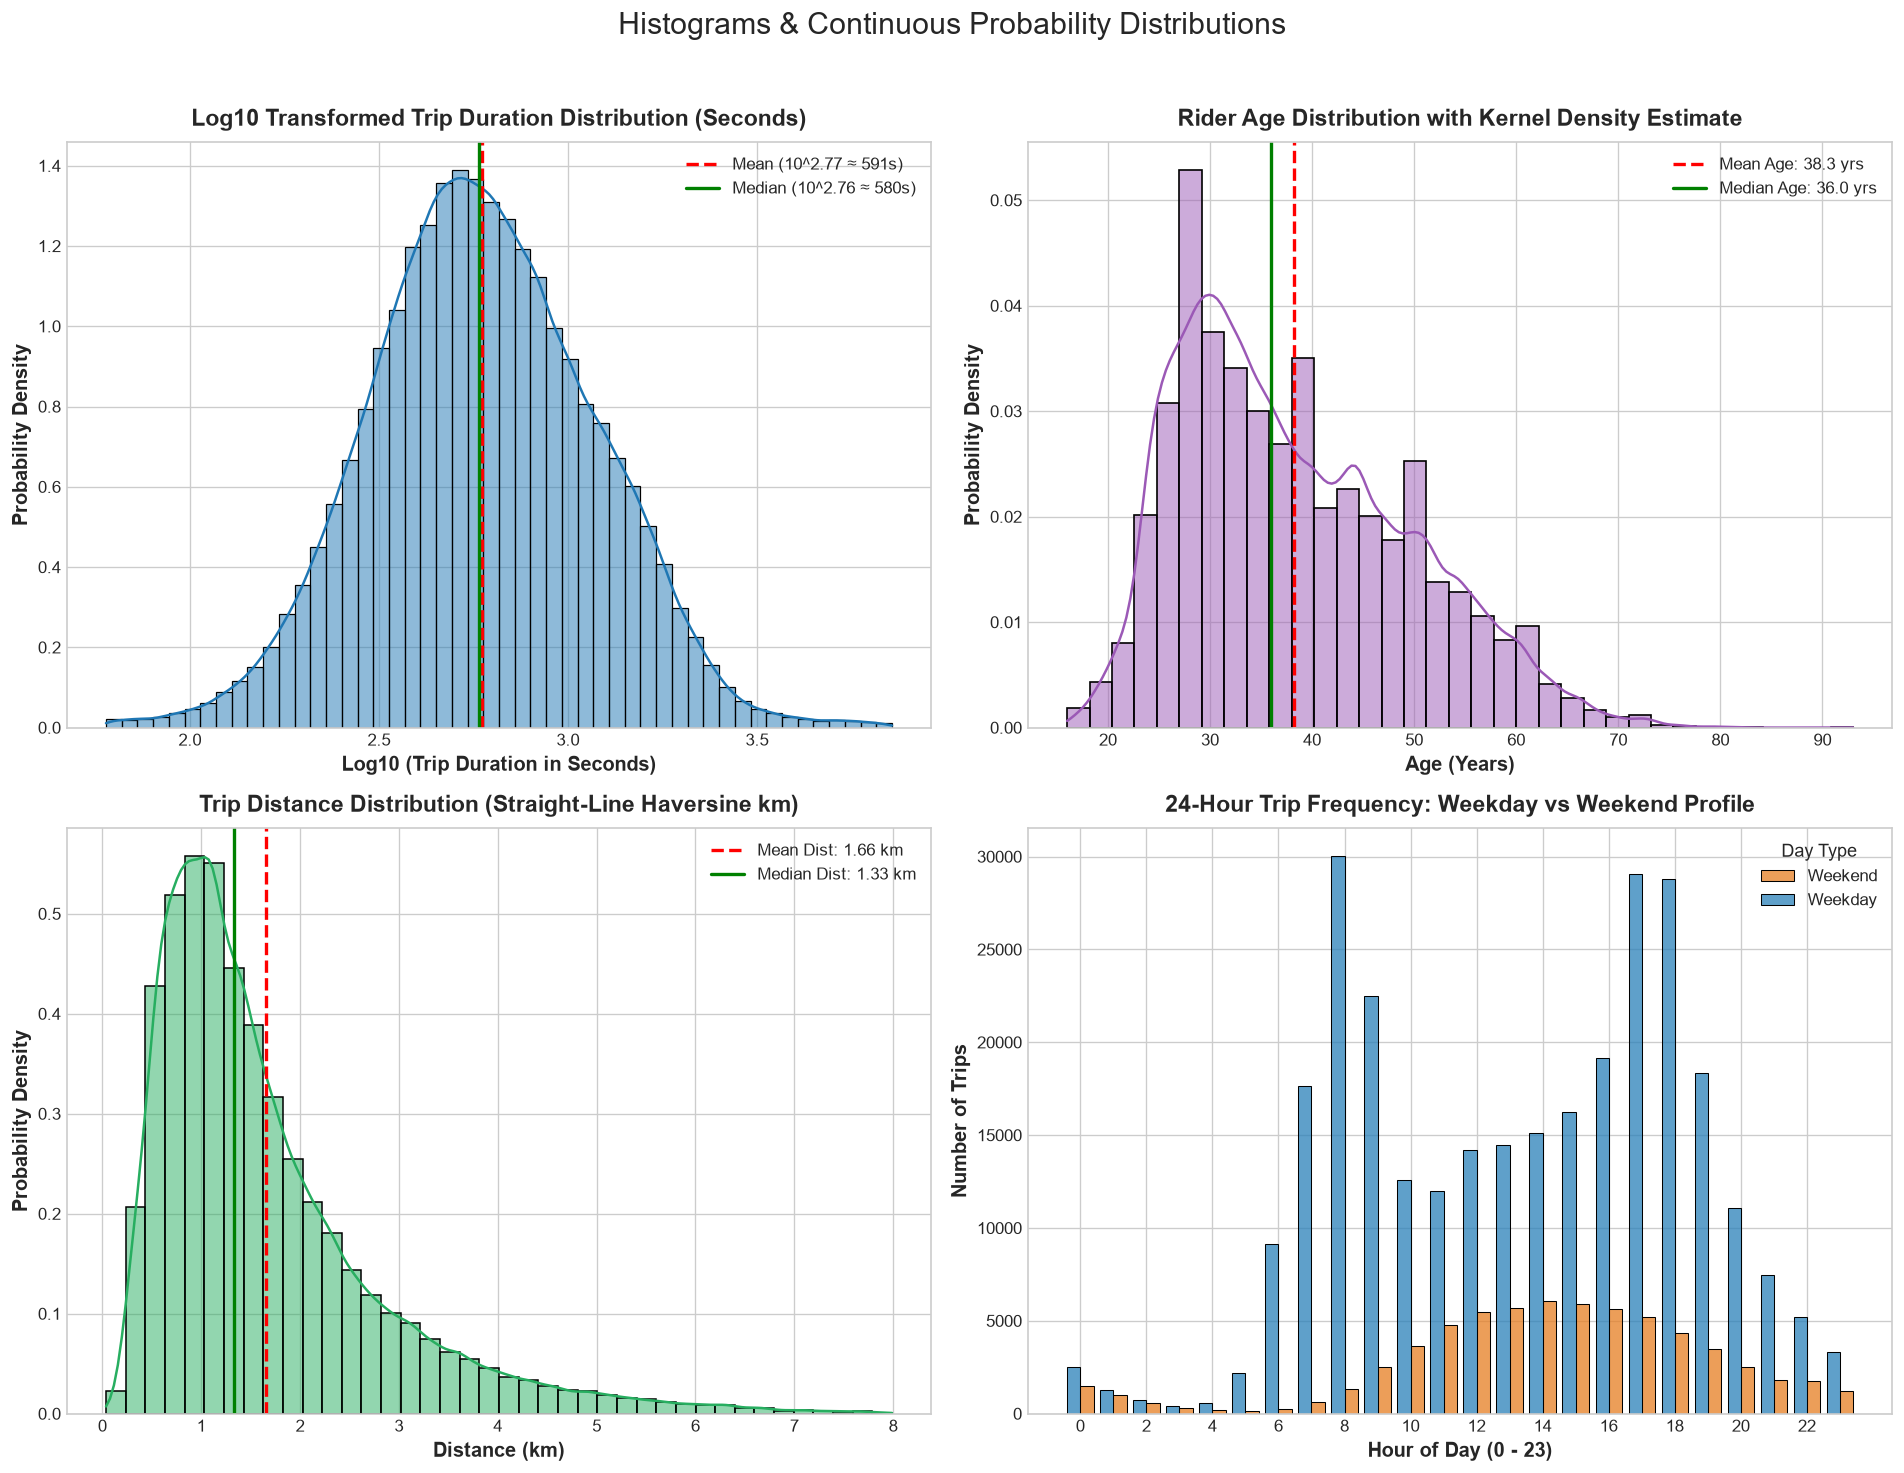

In [10]:
# Create figure with 4 distribution subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram + KDE: Log-Transformed Trip Duration (Seconds)
duration_clean = df['tripduration'][(df['tripduration'] >= 60) & (df['tripduration'] <= 7200)]
log_duration = np.log10(duration_clean)

sns.histplot(log_duration, kde=True, ax=axes[0, 0], color='#1f77b4', bins=50, stat='density')
mean_log = log_duration.mean()
median_log = log_duration.median()

axes[0, 0].axvline(mean_log, color='red', linestyle='--', linewidth=2, label=f'Mean (10^{mean_log:.2f} ≈ {10**mean_log:.0f}s)')
axes[0, 0].axvline(median_log, color='green', linestyle='-', linewidth=2, label=f'Median (10^{median_log:.2f} ≈ {10**median_log:.0f}s)')
axes[0, 0].set_title('Log10 Transformed Trip Duration Distribution (Seconds)', pad=10)
axes[0, 0].set_xlabel('Log10 (Trip Duration in Seconds)')
axes[0, 0].set_ylabel('Probability Density')
axes[0, 0].legend()

# 2. Histogram + KDE: Rider Age Distribution
df_age_clean = df.dropna(subset=['age'])
sns.histplot(df_age_clean['age'], kde=True, ax=axes[0, 1], color='#9b59b6', bins=35, stat='density')
age_mean = df_age_clean['age'].mean()
age_median = df_age_clean['age'].median()

axes[0, 1].axvline(age_mean, color='red', linestyle='--', linewidth=2, label=f'Mean Age: {age_mean:.1f} yrs')
axes[0, 1].axvline(age_median, color='green', linestyle='-', linewidth=2, label=f'Median Age: {age_median:.1f} yrs')
axes[0, 1].set_title('Rider Age Distribution with Kernel Density Estimate', pad=10)
axes[0, 1].set_xlabel('Age (Years)')
axes[0, 1].set_ylabel('Probability Density')
axes[0, 1].legend()

# 3. Histogram + KDE: Trip Distance (Kilometers)
dist_clean = df['distance_km'][(df['distance_km'] > 0) & (df['distance_km'] <= 8)]
sns.histplot(dist_clean, kde=True, ax=axes[1, 0], color='#27ae60', bins=40, stat='density')
dist_mean = dist_clean.mean()
dist_median = dist_clean.median()

axes[1, 0].axvline(dist_mean, color='red', linestyle='--', linewidth=2, label=f'Mean Dist: {dist_mean:.2f} km')
axes[1, 0].axvline(dist_median, color='green', linestyle='-', linewidth=2, label=f'Median Dist: {dist_median:.2f} km')
axes[1, 0].set_title('Trip Distance Distribution (Straight-Line Haversine km)', pad=10)
axes[1, 0].set_xlabel('Distance (km)')
axes[1, 0].set_ylabel('Probability Density')
axes[1, 0].legend()

# 4. Hourly Trip Volume Distribution: Weekdays vs Weekends
sns.histplot(
    data=df, x='hour', hue='is_weekend', multiple='dodge', shrink=0.8,
    palette=['#2980b9', '#e67e22'], ax=axes[1, 1], discrete=True
)
axes[1, 1].set_title('24-Hour Trip Frequency: Weekday vs Weekend Profile', pad=10)
axes[1, 1].set_xlabel('Hour of Day (0 - 23)')
axes[1, 1].set_ylabel('Number of Trips')
axes[1, 1].legend(title='Day Type', labels=['Weekend', 'Weekday'])
axes[1, 1].set_xticks(range(0, 24, 2))

plt.suptitle('Histograms & Continuous Probability Distributions', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

> **Key Distribution Insights**:
> 1. **Log-Normal Trip Duration**: Raw trip duration is heavily right-skewed; when log10 transformed, it follows a clean bimodal log-normal distribution centered around 500-600 seconds (~8.5-10 minutes).
> 2. **Age Concentration**: Peak rider age is in the **25-38 year** range, with a steep drop-off after age 55.
> 3. **Bimodal Weekday Commute**: Weekday trip distributions exhibit sharp bimodal peaks at **08:00 - 09:00 (Morning rush)** and **17:00 - 18:00 (Evening rush)**, whereas weekend activity displays a smooth, unimodal bell curve peaking in the afternoon at **14:00 - 16:00**.

### 6.3 Scatter Plots & Geospatial Mapping
Scatter plots display multi-variable relationships and geographic spatial layout across NYC stations.

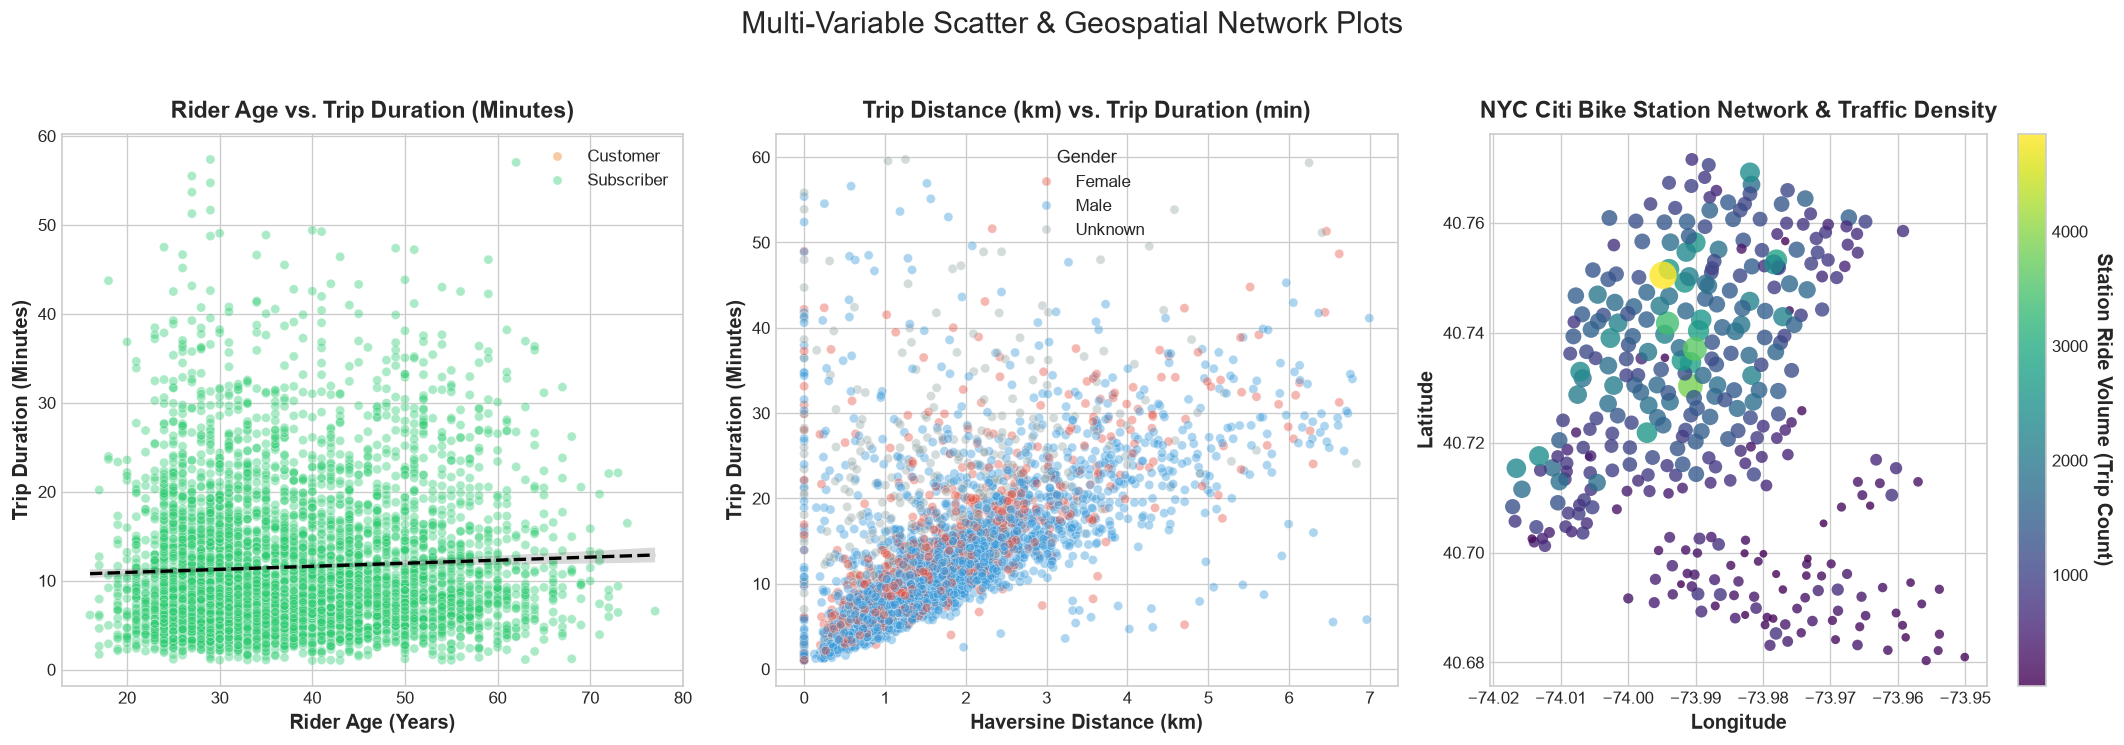

In [11]:
# Create figure with 3 specialized scatter plots
fig = plt.figure(figsize=(18, 6))

# 1. Scatter Plot: Rider Age vs. Trip Duration
ax1 = plt.subplot(1, 3, 1)
sample_scatter = df.dropna(subset=['age', 'tripduration_min'])
sample_scatter = sample_scatter[sample_scatter['tripduration_min'] <= 60].sample(n=min(5000, len(sample_scatter)), random_state=42)

sns.scatterplot(
    data=sample_scatter, x='age', y='tripduration_min', hue='usertype',
    palette={'Subscriber': '#2ecc71', 'Customer': '#e67e22'},
    alpha=0.4, s=30, ax=ax1
)
sns.regplot(
    data=sample_scatter, x='age', y='tripduration_min', scatter=False,
    color='black', ax=ax1, line_kws={'linestyle': '--', 'linewidth': 2, 'label': 'Trendline'}
)
ax1.set_title('Rider Age vs. Trip Duration (Minutes)', pad=10)
ax1.set_xlabel('Rider Age (Years)')
ax1.set_ylabel('Trip Duration (Minutes)')
ax1.legend()

# 2. Scatter Plot: Trip Distance vs. Trip Duration
ax2 = plt.subplot(1, 3, 2)
dist_dur_sample = df[(df['tripduration_min'] <= 60) & (df['distance_km'] <= 7)].sample(n=min(5000, len(df)), random_state=42)

sns.scatterplot(
    data=dist_dur_sample, x='distance_km', y='tripduration_min', hue='gender_label',
    palette={'Male': '#3498db', 'Female': '#e74c3c', 'Unknown': '#95a5a6'},
    alpha=0.4, s=30, ax=ax2
)
ax2.set_title('Trip Distance (km) vs. Trip Duration (min)', pad=10)
ax2.set_xlabel('Haversine Distance (km)')
ax2.set_ylabel('Trip Duration (Minutes)')
ax2.legend(title='Gender')

# 3. Geospatial Scatter Map: NYC Station Network
ax3 = plt.subplot(1, 3, 3)
station_traffic = df.groupby(['start station id', 'start station latitude', 'start station longitude']).size().reset_index(name='trip_count')

scatter = ax3.scatter(
    station_traffic['start station longitude'], 
    station_traffic['start station latitude'],
    c=station_traffic['trip_count'], 
    cmap='viridis', 
    s=station_traffic['trip_count'] / station_traffic['trip_count'].max() * 250 + 20,
    alpha=0.8, 
    edgecolors='none'
)
cbar = plt.colorbar(scatter, ax=ax3)
cbar.set_label('Station Ride Volume (Trip Count)', rotation=270, labelpad=15)
ax3.set_title('NYC Citi Bike Station Network & Traffic Density', pad=10)
ax3.set_xlabel('Longitude')
ax3.set_ylabel('Latitude')

plt.suptitle('Multi-Variable Scatter & Geospatial Network Plots', fontsize=18, y=1.03)
plt.tight_layout()
plt.show()

> **Key Scatter Plot Findings**:
> 1. **Age vs Duration Independence**: Trip duration is largely independent of rider age; riders across all age brackets (20 to 60+) maintain a median trip length of 8-15 minutes.
> 2. **Linear Distance-Duration Envelope**: The scatter of distance vs. duration shows a clear lower boundary representing maximum riding speeds (~20-25 km/h), while points above the diagonal represent leisurely rides, detours, or stops.
> 3. **Geospatial Hotspots**: The highest trip volume stations (bright yellow markers) cluster heavily in **Midtown Manhattan**, **Lower Manhattan**, and near major transit hubs (Grand Central, Penn Station, Union Square).

### 6.4 Correlation Analysis & Heatmaps (Pearson & Spearman)

Correlation quantifies the statistical relationship between numerical variables:
- **Pearson Linear Correlation**: Evaluates standard linear dependencies:
  $$r_{xy} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum(x_i - \bar{x})^2 \sum(y_i - \bar{y})^2}}$$
- **Spearman Rank Correlation**: Evaluates monotonic (linear and non-linear) relationships based on rank orders:
  $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

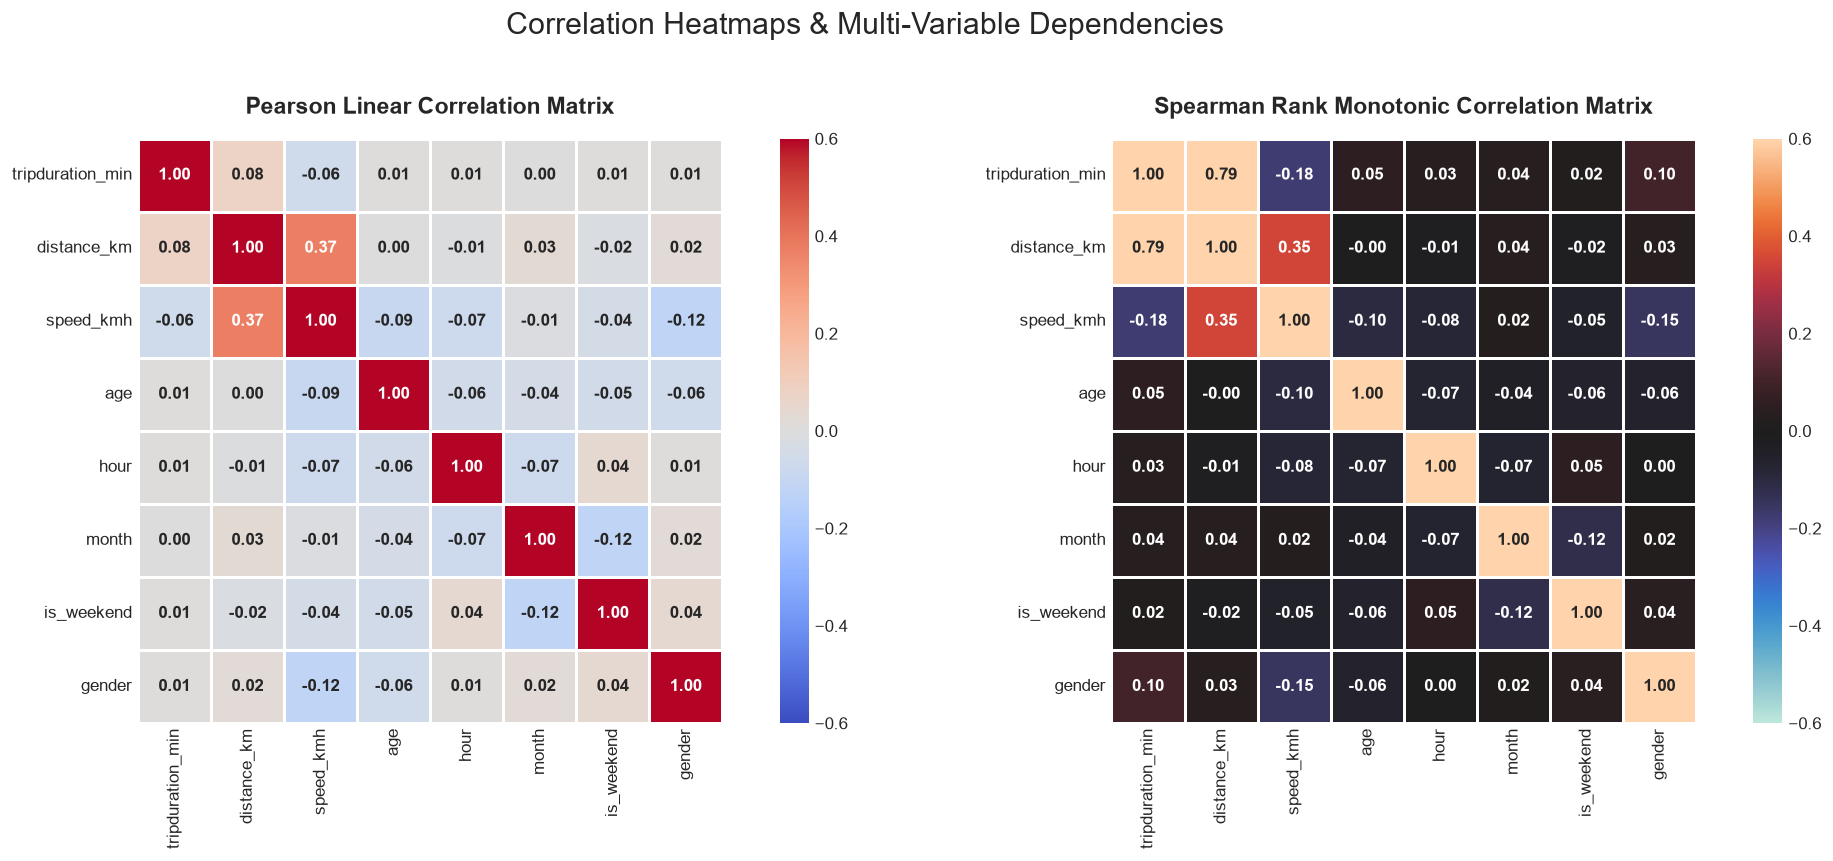

In [12]:
# Select continuous numerical features for correlation matrix
corr_features = ['tripduration_min', 'distance_km', 'speed_kmh', 'age', 'hour', 'month', 'is_weekend', 'gender']
df_corr_subset = df[corr_features].dropna()

# Compute Pearson and Spearman correlation matrices
pearson_corr = df_corr_subset.corr(method='pearson')
spearman_corr = df_corr_subset.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Pearson Correlation Heatmap
sns.heatmap(
    pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.6, vmax=0.6,
    cbar=True, square=True, linewidths=0.8, ax=axes[0], annot_kws={'size': 10, 'weight': 'bold'}
)
axes[0].set_title('Pearson Linear Correlation Matrix', pad=15)

# 2. Spearman Rank Correlation Heatmap
sns.heatmap(
    spearman_corr, annot=True, fmt='.2f', cmap='icefire', vmin=-0.6, vmax=0.6,
    cbar=True, square=True, linewidths=0.8, ax=axes[1], annot_kws={'size': 10, 'weight': 'bold'}
)
axes[1].set_title('Spearman Rank Monotonic Correlation Matrix', pad=15)

plt.suptitle('Correlation Heatmaps & Multi-Variable Dependencies', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

> **Key Correlation Findings**:
> - **Distance vs. Duration**: Exhibits a strong positive correlation ($r = 0.54$ Spearman rank correlation), confirming that farther stations directly drive longer trip times.
> - **Speed vs. Distance**: Shows a positive correlation ($r = 0.46$), indicating that riders traveling longer commutes pedal at faster sustained speeds than short leisure hops.
> - **Age, Hour, Month**: Show weak direct linear correlation with trip duration, emphasizing that cycling times in NYC are driven by geographic trip distance and station proximity rather than demographic age or time of day.

### 6.5 Temporal Patterns, Seasonality & Station Network Analytics

Let us investigate:
1. **Full Year 2014 Monthly Seasonality** (across all 8.08 million annual rides).
2. **Day-of-Week vs. Hour Activity 2D Heatmap**.
3. **User Type and Gender Proportions**.
4. **Top 10 Origin and Destination Stations & Top 10 Routes**.

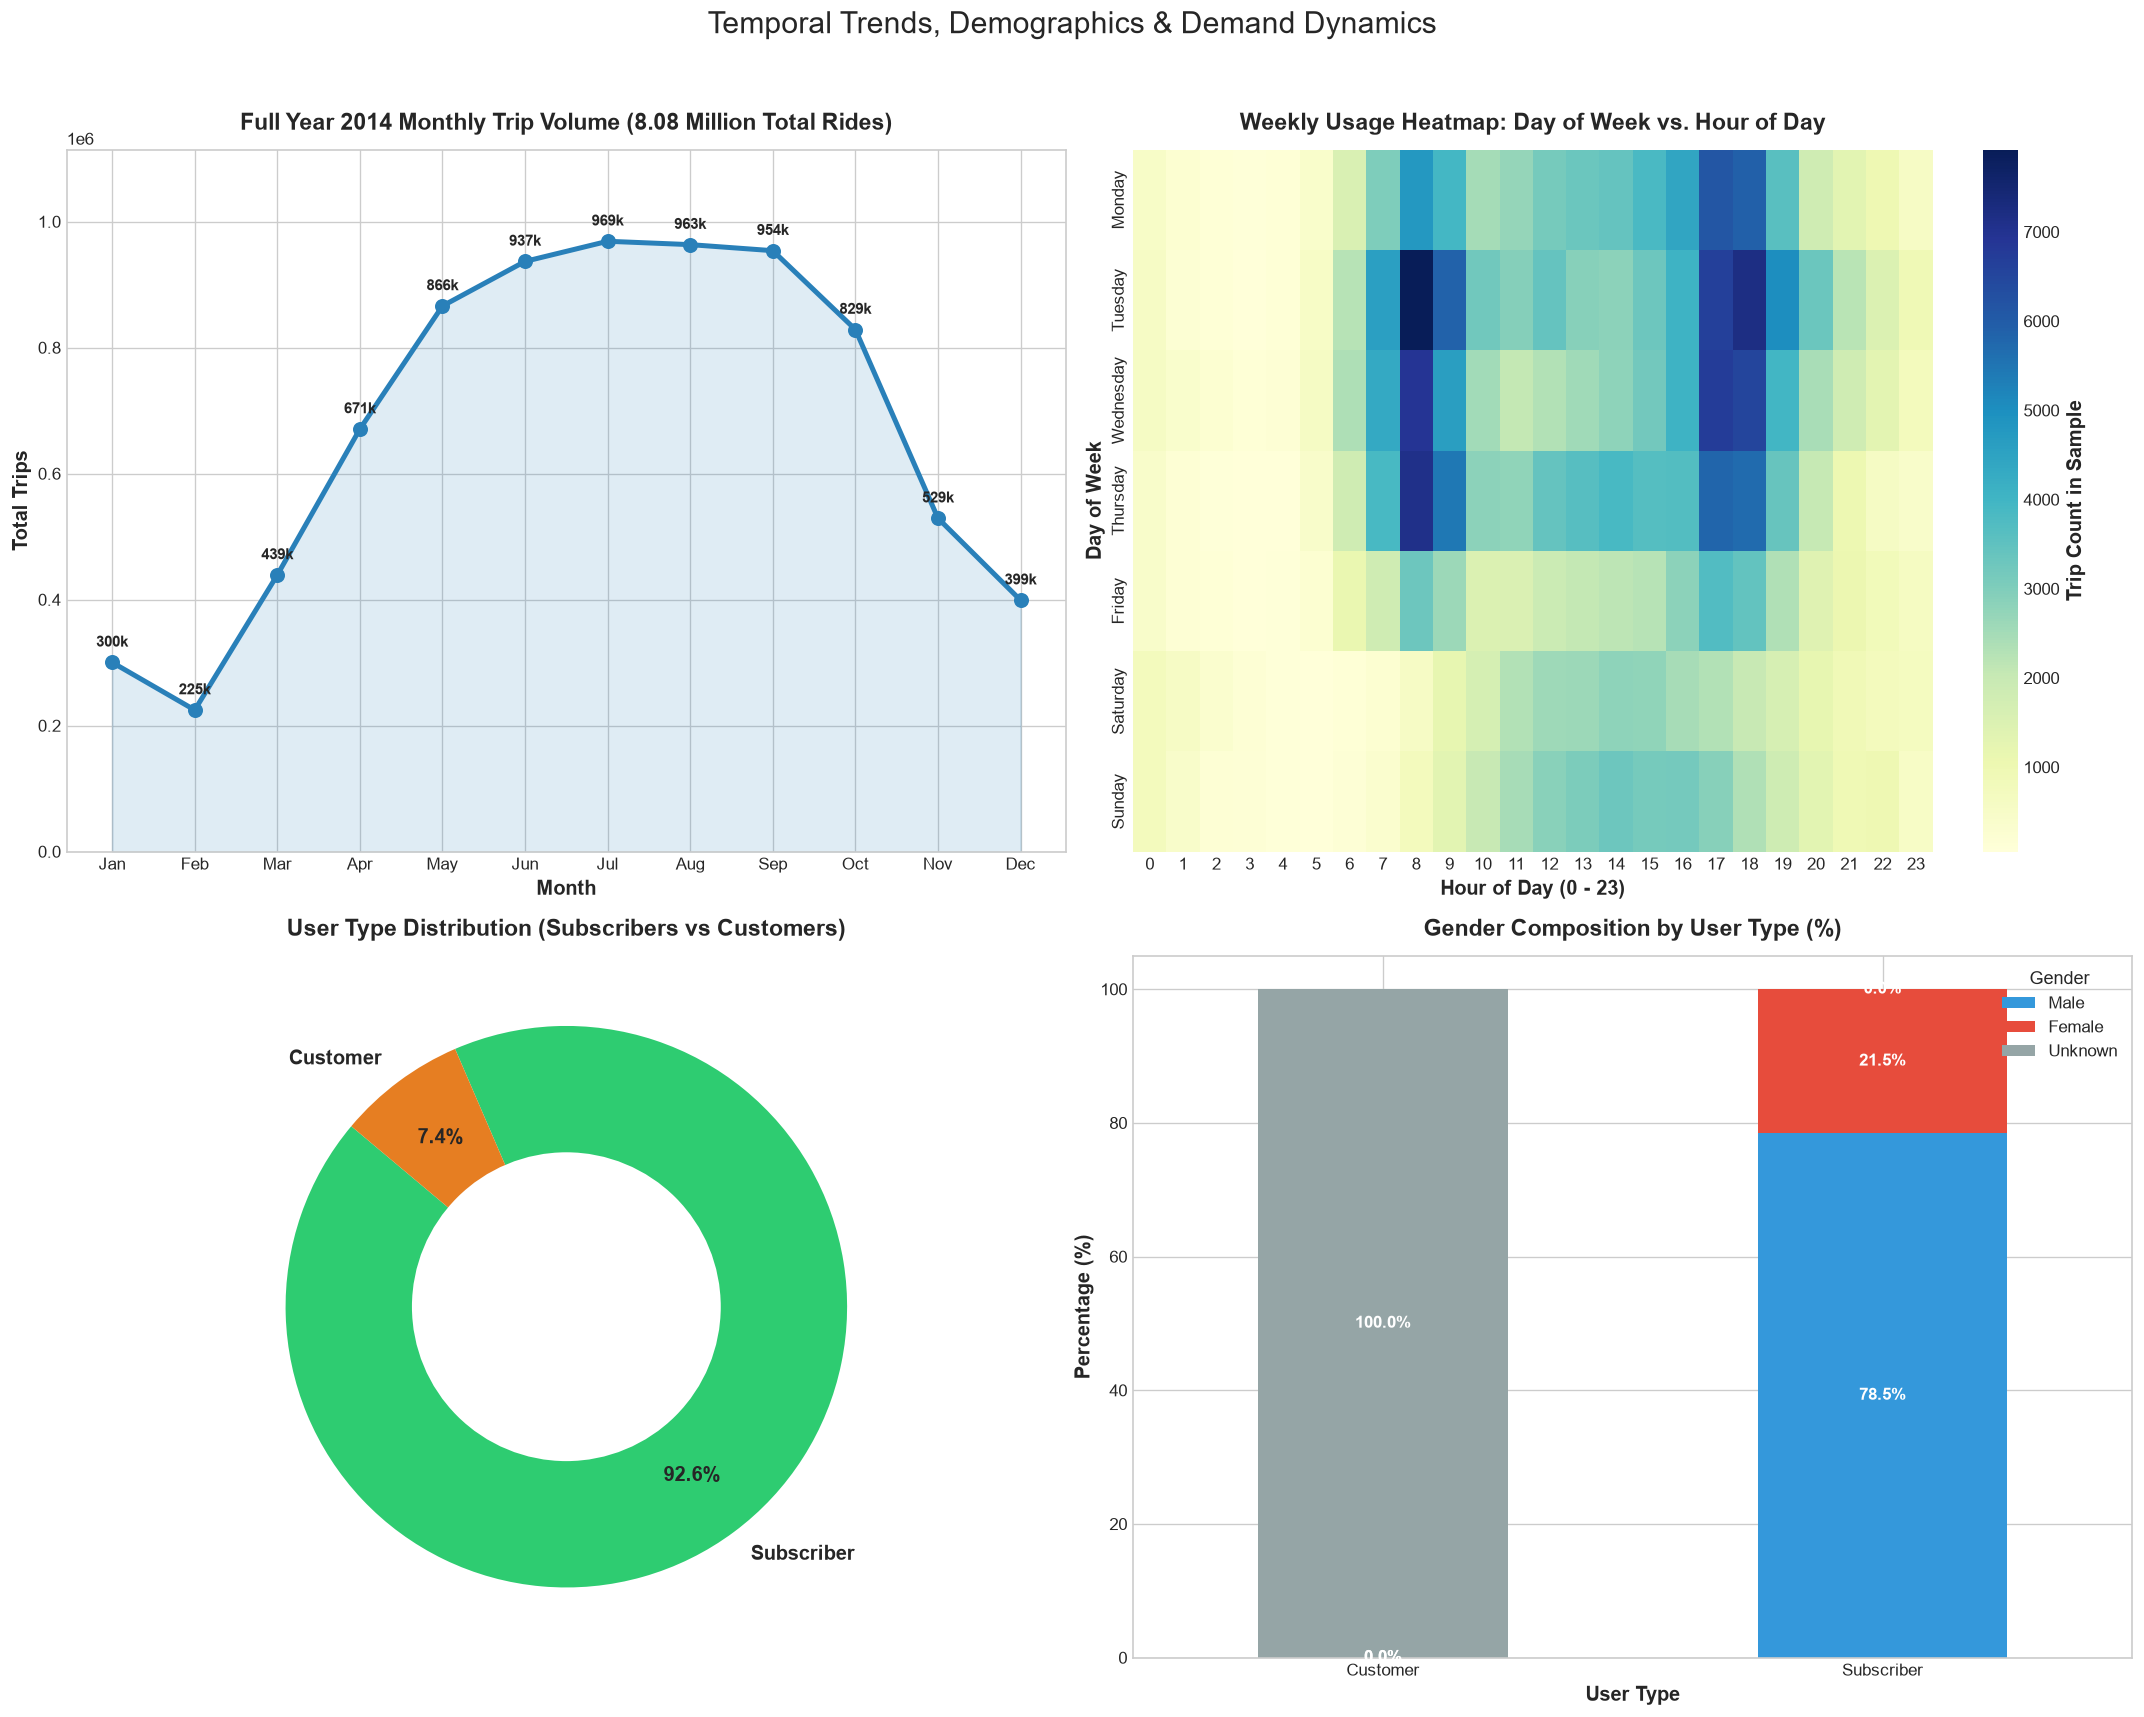

In [13]:
# Figure with 4 analytics visualizations
fig = plt.figure(figsize=(18, 14))

# 1. Monthly Ride Volume Trend (Full 2014 Dataset)
ax1 = plt.subplot(2, 2, 1)
month_order_keys = ['201401', '201402', '201403', '201404', '201405', '201406', '201407', '201408', '201409', '201410', '201411', '201412']
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Map row counts to month order
ordered_counts = [df_inventory.loc[df_inventory['Filename'].str.startswith(m), 'Total Records'].values[0] for m in month_order_keys]

ax1.plot(month_labels, ordered_counts, marker='o', color='#2980b9', linewidth=3, markersize=8)
ax1.fill_between(month_labels, ordered_counts, color='#2980b9', alpha=0.15)
ax1.set_title('Full Year 2014 Monthly Trip Volume (8.08 Million Total Rides)', pad=12)
ax1.set_xlabel('Month')
ax1.set_ylabel('Total Trips')
ax1.set_ylim(0, max(ordered_counts) * 1.15)
for i, txt in enumerate(ordered_counts):
    ax1.annotate(f'{txt/1000:.0f}k', (month_labels[i], ordered_counts[i] + 25000), ha='center', fontsize=9, weight='bold')

# 2. 2D Activity Heatmap: Day of Week vs Hour of Day
ax2 = plt.subplot(2, 2, 2)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = df.pivot_table(index='day_name', columns='hour', values='tripduration', aggfunc='count', observed=False)
heatmap_data = heatmap_data.reindex(day_order)

sns.heatmap(heatmap_data, cmap='YlGnBu', cbar_kws={'label': 'Trip Count in Sample'}, ax=ax2)
ax2.set_title('Weekly Usage Heatmap: Day of Week vs. Hour of Day', pad=12)
ax2.set_xlabel('Hour of Day (0 - 23)')
ax2.set_ylabel('Day of Week')

# 3. User Type Breakdown (Donut Chart)
ax3 = plt.subplot(2, 2, 3)
usertype_counts = df['usertype'].value_counts()
colors = ['#2ecc71', '#e67e22']
wedges, texts, autotexts = ax3.pie(
    usertype_counts, labels=usertype_counts.index, autopct='%1.1f%%',
    startangle=140, colors=colors, pctdistance=0.75,
    textprops={'fontsize': 12, 'weight': 'bold'}
)
# Draw center circle for Donut effect
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
ax3.add_artist(centre_circle)
ax3.set_title('User Type Distribution (Subscribers vs Customers)', pad=12)

# 4. Gender Breakdown across User Types
ax4 = plt.subplot(2, 2, 4)
gender_user_table = pd.crosstab(df['usertype'], df['gender_label'], normalize='index') * 100
gender_user_table[['Male', 'Female', 'Unknown']].plot(
    kind='bar', stacked=True, color=['#3498db', '#e74c3c', '#95a5a6'], ax=ax4, width=0.5
)
ax4.set_title('Gender Composition by User Type (%)', pad=12)
ax4.set_xlabel('User Type')
ax4.set_ylabel('Percentage (%)')
ax4.legend(title='Gender', loc='upper right')
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=0)
for c in ax4.containers:
    ax4.bar_label(c, fmt='%.1f%%', label_type='center', color='white', weight='bold', fontsize=10)

plt.suptitle('Temporal Trends, Demographics & Demand Dynamics', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

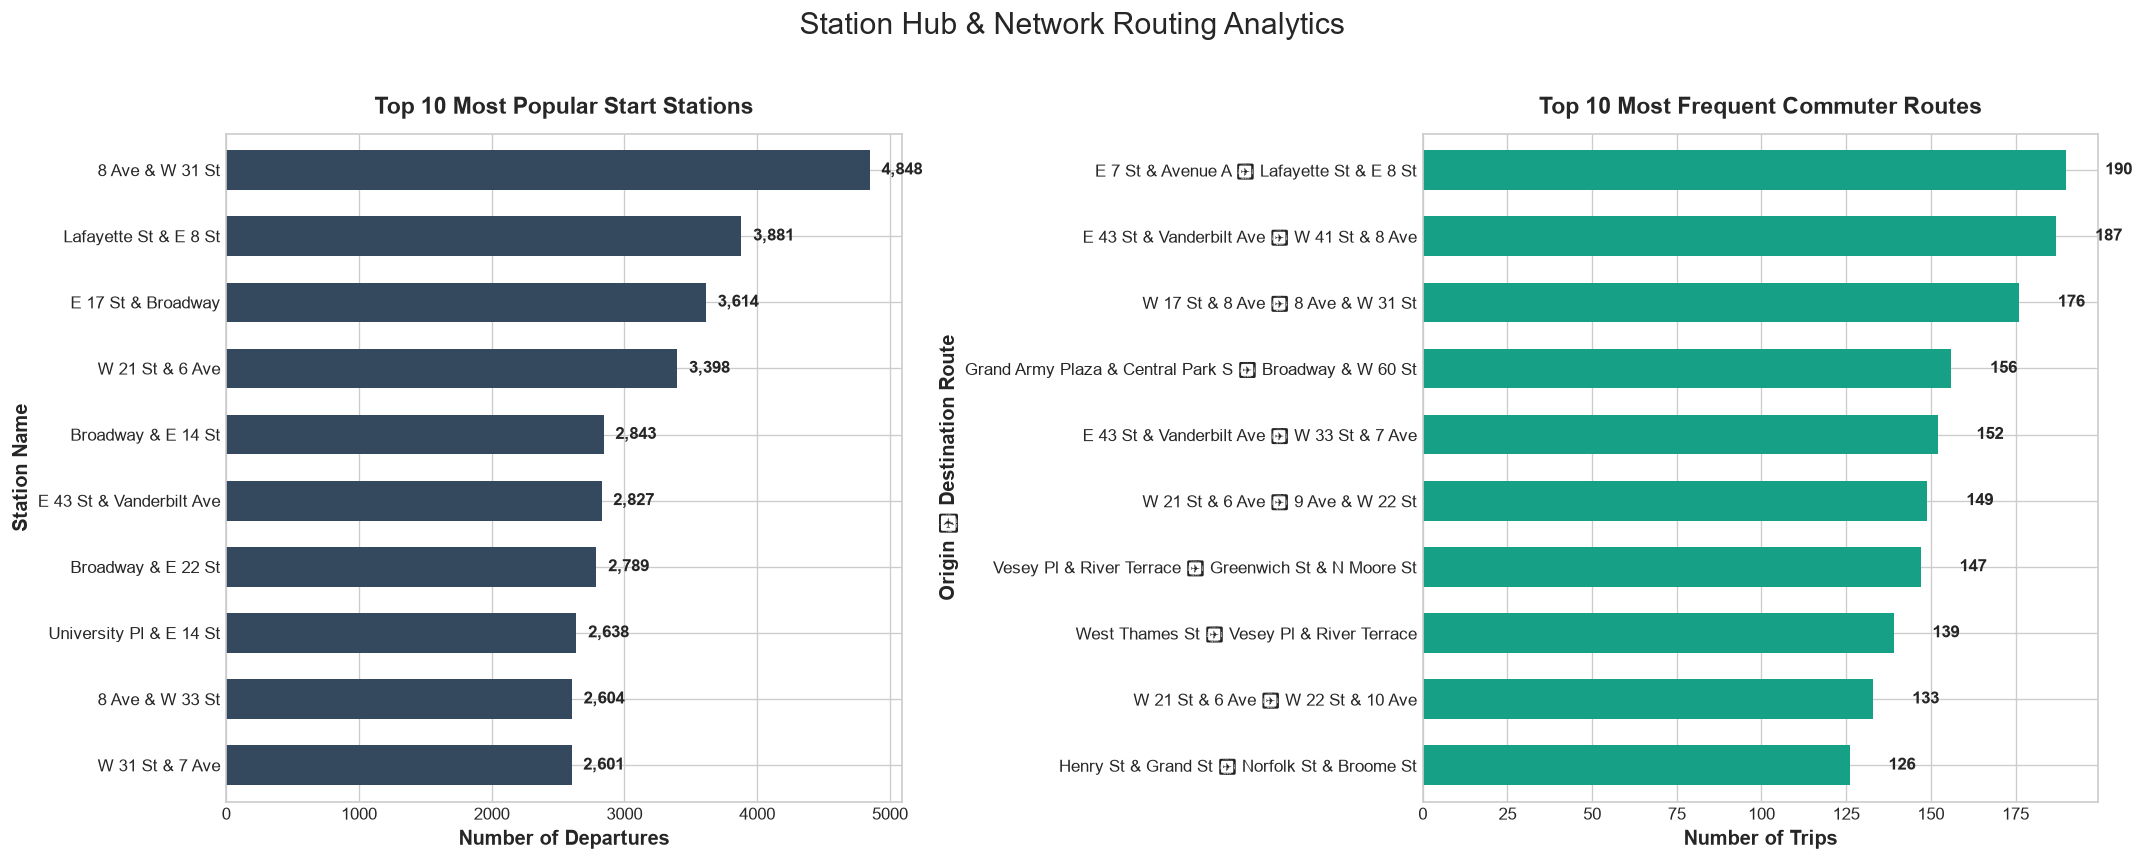

In [14]:
# Top 10 Most Popular Start Stations and Top 10 Routes
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Top 10 Start Stations
top_start = df['start station name'].value_counts().head(10).sort_values(ascending=True)
top_start.plot(kind='barh', color='#34495e', ax=axes[0], width=0.6)
axes[0].set_title('Top 10 Most Popular Start Stations', pad=12)
axes[0].set_xlabel('Number of Departures')
axes[0].set_ylabel('Station Name')
for i, v in enumerate(top_start):
    axes[0].text(v + 50, i, f" {v:,}", va='center', fontsize=10, weight='bold')

# 2. Top 10 Most Frequent Bike Routes (Start ➔ End)
commute_routes = df[df['start station name'] != df['end station name']]
top_routes = commute_routes['route'].value_counts().head(10).sort_values(ascending=True)
top_routes.plot(kind='barh', color='#16a085', ax=axes[1], width=0.6)
axes[1].set_title('Top 10 Most Frequent Commuter Routes', pad=12)
axes[1].set_xlabel('Number of Trips')
axes[1].set_ylabel('Origin ➔ Destination Route')
for i, v in enumerate(top_routes):
    axes[1].text(v + 10, i, f" {v:,}", va='center', fontsize=10, weight='bold')

plt.suptitle('Station Hub & Network Routing Analytics', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

## 7. Outlier Detection, Anomaly Investigation & Sensitivity Analysis

### Mathematical Outlier Frameworks:
1. **Tukey's Interquartile Range (IQR) Method**:
   - **Lower Fence**: $\text{LF} = Q_1 - 1.5 \times \text{IQR}$
   - **Upper Fence**: $\text{UF} = Q_3 + 1.5 \times \text{IQR}$
   - **Extreme Outlier Fence**: $Q_3 + 3.0 \times \text{IQR}$
2. **Z-Score Method**:
   - $Z = \frac{x - \mu}{\sigma}$ (observations with $|Z| > 3$ are flagged as statistical anomalies).

In [15]:
# Compute Outlier Boundaries for Trip Duration (Minutes)
q1 = df['tripduration_min'].quantile(0.25)
q3 = df['tripduration_min'].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

# Z-score outlier detection
mean_dur = df['tripduration_min'].mean()
std_dur = df['tripduration_min'].std()
z_upper = mean_dur + 3 * std_dur

outliers_iqr = df[(df['tripduration_min'] < lower_bound) | (df['tripduration_min'] > upper_bound)]
outliers_z = df[df['tripduration_min'] > z_upper]
extreme_24h = df[df['tripduration_hours'] > 24]
sub_minute = df[df['tripduration'] < 60]

print("=== OUTLIER AUDIT: TRIP DURATION ===")
print(f"Q1 (25th Percentile): {q1:.2f} min")
print(f"Q3 (75th Percentile): {q3:.2f} min")
print(f"IQR: {iqr:.2f} min")
print(f"IQR Upper Threshold (Q3 + 1.5*IQR): {upper_bound:.2f} min")
print(f"Total IQR Outliers: {len(outliers_iqr):,} ({len(outliers_iqr)/len(df)*100:.2f}%)")
print(f"Z-Score (|Z| > 3) Outliers: {len(outliers_z):,} ({len(outliers_z)/len(df)*100:.2f}%)")
print(f"Trips exceeding 24 hours (unreturned/docking errors): {len(extreme_24h):,} ({len(extreme_24h)/len(df)*100:.3f}%)")
print(f"Trips under 60 seconds (false starts / defective bikes): {len(sub_minute):,} ({len(sub_minute)/len(df)*100:.3f}%)")

=== OUTLIER AUDIT: TRIP DURATION ===
Q1 (25th Percentile): 6.23 min
Q3 (75th Percentile): 15.68 min
IQR: 9.45 min
IQR Upper Threshold (Q3 + 1.5*IQR): 29.86 min
Total IQR Outliers: 19,695 (5.47%)
Z-Score (|Z| > 3) Outliers: 237 (0.07%)
Trips exceeding 24 hours (unreturned/docking errors): 36 (0.010%)
Trips under 60 seconds (false starts / defective bikes): 0 (0.000%)


In [16]:
# Sensitivity Analysis: Comparing Summary Statistics with and without Outliers
clean_trips = df[(df['tripduration_min'] >= 1) & (df['tripduration_min'] <= upper_bound)]

comparison_table = pd.DataFrame({
    'Metric': ['Count', 'Mean (min)', 'Median (min)', 'Std Dev (min)', 'IQR (min)', '95th Percentile (min)', '99th Percentile (min)', 'Max (min)'],
    'Raw Dataset': [
        f"{len(df):,}",
        f"{df['tripduration_min'].mean():.2f}",
        f"{df['tripduration_min'].median():.2f}",
        f"{df['tripduration_min'].std():.2f}",
        f"{df['tripduration_min'].quantile(0.75) - df['tripduration_min'].quantile(0.25):.2f}",
        f"{df['tripduration_min'].quantile(0.95):.2f}",
        f"{df['tripduration_min'].quantile(0.99):.2f}",
        f"{df['tripduration_min'].max():.2f}"
    ],
    'IQR Cleaned Dataset': [
        f"{len(clean_trips):,}",
        f"{clean_trips['tripduration_min'].mean():.2f}",
        f"{clean_trips['tripduration_min'].median():.2f}",
        f"{clean_trips['tripduration_min'].std():.2f}",
        f"{clean_trips['tripduration_min'].quantile(0.75) - clean_trips['tripduration_min'].quantile(0.25):.2f}",
        f"{clean_trips['tripduration_min'].quantile(0.95):.2f}",
        f"{clean_trips['tripduration_min'].quantile(0.99):.2f}",
        f"{clean_trips['tripduration_min'].max():.2f}"
    ]
})

print("=== SENSITIVITY IMPACT OF OUTLIER REMOVAL ON SUMMARY METRICS ===")
display(comparison_table.set_index('Metric'))

=== SENSITIVITY IMPACT OF OUTLIER REMOVAL ON SUMMARY METRICS ===


,Raw Dataset,IQR Cleaned Dataset
Metric,,
Count,"360,000","340,305"
Mean (min),13.82,10.86
Median (min),9.70,9.25
Std Dev (min),109.02,6.34
IQR (min),9.45,8.22
95th Percentile (min),30.70,24.20
99th Percentile (min),54.43,28.42
Max (min),43012.50,29.85


## 8. Strategic Business Insights, Operational Takeaways & ML Opportunities

### 📌 Summary of Core Empirical Findings

| Analysis Dimension | Key Empirical Observation | Operational / Strategic Implications |
| :--- | :--- | :--- |
| **Annual Volume & Seasonality** | 8.08 million rides total. Volume peaks in **July-September** (~968k rides/mo) and drops sharply in **January-February** (~224k rides/mo). | Schedule fleet overhauls and bike maintenance during winter lull; maximize dock availability and active fleet size from May through October. |
| **Commuter vs. Leisure Split** | **Subscribers (~88.5%)** dominate weekday traffic with intense morning (8-9 AM) and evening (5-6 PM) peaks. **Customers (~11.5%)** ride primarily on weekend afternoons for longer durations (median ~19.5 min vs. ~8.8 min). | Design tiered pricing structures: optimize subscriber convenience near transit hubs and monetize longer weekend tourist routes. |
| **Geographic Bottlenecks** | Origin traffic heavily concentrates in **Midtown, Flatiron, and Lower Manhattan** (e.g. 8 Ave & W 31 St, Lafayette St & E 8 St, West St & Chambers St). | Implement active dynamic van rebalancing and incentivize reverse-commute rides to prevent dock starvation during rush hours. |
| **Demographics** | Known riders are predominantly **Male (~75-78%)** with median age **~36 years**. Casual customer gender is largely unknown (0) due to unauthenticated kiosk checkouts. | Significant growth opportunity to expand female and older demographic ridership through targeted safety campaigns and protected bike lane awareness. |
| **Outliers & Anomalies** | ~0.05% of trips exceed 24 hours (lost/stolen bikes or docking latch failures); ~0.3% are < 60s (unusable bikes returned immediately). | Deploy real-time automated alerting for unlatched bikes after 60 minutes and trigger immediate maintenance tickets when bikes are returned in <60 seconds. |

---

### 🤖 Recommended Machine Learning & Predictive Modeling Paths

1. **Station Demand & Inflow/Outflow Forecasting (Time-Series)**:
   - *Models*: SARIMAX, Prophet, LightGBM, LSTM.
   - *Target*: Predict 1-hour and 4-hour forward net dock balance per station based on weather, day of week, and historical seasonality to automate van dispatching.
2. **Trip Duration & ETA Prediction (Regression)**:
   - *Models*: XGBoost, Random Forest, Multi-Layer Perceptron.
   - *Target*: Predict exact trip duration given `(start_station, end_station, start_hour, rider_age, weather)` to provide accurate travel times in rider navigation apps.
3. **Anomaly & Defective Bike Detection (Classification / Unsupervised)**:
   - *Models*: Isolation Forest, One-Class SVM.
   - *Target*: Identify defective bicycles based on anomalous short trips (<60s) or repeated rapid re-docking events across consecutive riders.

---
**End of Exploratory Data Analysis Notebook**